# EA4 PGS + Updated Phenotypic Correlations — Predicted Conditions vs Observed Correlations

The NPE fits of conditions 01–04 (fit to the observed PGS **and** phenotypic correlations; the v2
fits of October 2026, not retrained) were applied to the EA4 PGS correlations
(`observed_correlations_PGS_ea4new.csv`) and the updated EA phenotypic correlations
(`observed_correlations_pheno_021126.csv`). Each condition was then simulated at the posterior means
(`Scripts/run_rc_paper/run_predicted_condition_rc_*.py`, 100 replicates, compiled with
`compile_predicted_condition.py`), and this notebook compares the simulated relative correlations with
the observed ones. The run before this one, with the EA4 PGS but the old phenotypic correlations, is in
`Analysis_NPE_ea4new.ipynb`; the v1 and v2 runs are in `Analysis_NPE.ipynb`.

**Observed data.** Both files have the same 26 relationship types: the 16 the NPE fits use, and 10 more
(`SC`, `PSCC`, `MPS`, `MSCM`, `SMPS`, `MPSC`, `SCMP`, `MPSCM`, `MSMPS`, `SMSCM`) that were never in the
training data, so they test the fitted models out of sample. Unlike the earlier runs, the 10 new types
now have observed phenotypic correlations too.

**Reading the figures.** For each relationship type, the bars are the simulated PGS correlations
(blue) and phenotypic correlations (teal; error bars: SD across the 100 replicates); the diamond on each
bar is the observed value. All 26 types are sorted by the observed PGS correlation.

**Fit criterion.** Simulated and observed correlations are compared on Fisher's z scale
(z = arctanh r), where the sampling variance of a correlation no longer depends on its size, so misses
on large and small correlations count alike. The box in each figure gives the RMSE of z over the 26
types; the table under the figure also splits it into the 16 fit types and the 10 new ones and adds the
bias (mean of simulated − observed z). For a small correlation a z difference is close to the raw
difference; at r ≈ 0.4 it is about 1.2 times larger, at r ≈ 0.6 about 1.6 times.

**Results in short.**
- **The estimates barely move.** No estimate changes by more than 0.03 from the earlier EA4 run, except
  `f11` in condition 03 (0.213 → 0.158, within its posterior SD of 0.079).
- **01 and 04 reproduce the PGS correlations closely** (RMSE 0.02–0.03 on Fisher's z), the 10 new
  types about as well as the fit types. 04 also fits the phenotypic correlations best (RMSE 0.047).
- **The new phenotypic correlations test the models out of sample.** 01 under-predicts the in-law
  correlations among them, as it does among the fit types; 04 over-predicts all 10, three in-law types
  about twofold; 02 and 03 over-predict all 10.
- **03 still fits poorly**: RMSE 0.10 for the PGS and 0.29 for the phenotypic correlations, against
  0.02–0.04 and 0.05–0.12 for the other conditions. That is slightly better than before because `f11` is
  lower. The observed sibling correlation is still below every training simulation, and the
  [last section](#condition-03-with-the-updated-data) shows the earlier diagnosis holds.

Parameter meanings, the simulation model and the NPE are documented in the repository `README.md`.
`vg` sets the *environmental* variance (1 − `vg`); the genetic variance is ≈ 1, so founder heritability
is ≈ 1/(2 − `vg`).

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from pathlib import Path

# ── Paths and observed data ────────────────────────────────────────────────
script_dir = Path(".")
obs_pgs = pd.read_csv(script_dir / "observed_correlations_PGS_ea4new.csv").set_index("RelType")["Correlation"]
pheno = pd.read_csv(script_dir / "observed_correlations_pheno_021126.csv").set_index("RelType")
obs_pheno = pheno["Correlation"]
# the observed correlations of the earlier runs: old PGS (v1, v2) and old phenotypic (all earlier runs)
obs_pgs_old = pd.read_csv(script_dir / "observed_correlations_PGS.csv").set_index("RelType")["Correlation"]
obs_pheno_old = pd.read_csv(script_dir / "observed_correlations_pheno.csv").set_index("RelType")["Correlation"]

# the 16 relationship types the NPE fits use, and the 10 EA4 types not in the training data
TRAINING_TYPES = [t for t in obs_pgs_old.index if t in obs_pgs.index]
NEW_TYPES = [t for t in obs_pgs.index if t not in obs_pgs_old.index]
print(f"{len(TRAINING_TYPES)} fit types: {TRAINING_TYPES}")
print(f"{len(NEW_TYPES)} new types: {NEW_TYPES}")

# this run, and the EA4 PGS run with the old phenotypic correlations whose estimates it updates
RUNS = {"ea4pheno": "EA4 PGS + new pheno (this run)", "ea4new": "EA4 PGS + old pheno"}


def pred_path(fit, run="ea4pheno"):
    """Predicted-condition summary file of this run (ea4pheno) or of the earlier EA4 PGS run (ea4new)."""
    name = {"ea4pheno": f"predictions_ea4pheno/summary_statistics_{fit}_ea4pheno.csv",
            "ea4new": f"predictions/summary_statistics_{fit}_ea4new.csv"}[run]
    return script_dir / f"results_npe_unweighted_{fit}" / name


# condition -> NPE fit(s) giving its parameters, folder of its summary file and compared trait(s)
CONDITIONS = {
    "01DirAM": dict(title="Condition 01 — Direct AM", fits=["01DirAM_AE", "01DirAM_AFE"],
                    summary="01DirAM_AE", traits=[(1, "Trait 1 (AE)"), (2, "Trait 2 (AFE)")]),
    "02AElatentAM": dict(title="Condition 02 — AE latent AM", fits=["02AElatentAM"],
                         summary="02AElatentAM", traits=[(1, "Trait 1 (EA)")]),
    "03EnvLatentAM": dict(title="Condition 03 — Environmental latent AM", fits=["03EnvLatentAM"],
                          summary="03EnvLatentAM", traits=[(1, "Trait 1 (EA)")]),
    "04EAmigration": dict(title="Condition 04 — EA-driven migration", fits=["04EAmigration"],
                          summary="04EAmigration", traits=[(1, "Trait 1 (EA)")]),
}

MEANING = {
    "prop_h2_latent1": "share of trait-1 genetic variance not captured by the PGS",
    "prop_h2_latent2": "share of trait-2 genetic variance not captured by the PGS",
    "vg1": "sets the trait-1 environmental variance 1 − vg1 (founder h² ≈ 1/(2 − vg1))",
    "vg2": "sets the trait-2 environmental variance 1 − vg2",
    "am11": "spousal correlation on trait 1",
    "am22": "spousal correlation on trait 2",
    "f11": "vertical transmission, trait 1",
    "f22": "vertical transmission, trait 2",
    "s22": "shared family environment, trait 2 (no effect: the engine ignores s)",
    "re": "environmental correlation between the traits",
    "rg": "genetic correlation between the traits",
    "move_p": "fraction of each sex per island migrating each generation",
    "n_gen": "generations since the random founders (categorical posterior)",
}

# bar colours as in Analysis_NPE.ipynb: PGS blue, phenotypic teal; ACCENT marks the estimate in
# the condition-03 figure (reference palette slots 1-3, validated as a set)
BAR_COLORS = {"PGS": "#2a78d6", "Phenotypic": "#199e70"}
ACCENT = "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e1e0d9"


def show(df, precision=4):
    display(df.style.hide(axis="index").format(precision=precision, na_rep="–"))


def parameter_table(key):
    """Posterior of every estimated parameter, with its simulated range and the earlier EA4 (ea4new) value."""
    rows = []
    for fit in CONDITIONS[key]["fits"]:
        run = script_dir / f"results_npe_unweighted_{fit}"
        cfg = json.loads((run / "config.json").read_text())
        bounds = dict(zip(cfg["prior_params"], zip(cfg["prior_lower"], cfg["prior_upper"])))
        if cfg.get("count_param"):
            bounds[cfg["count_param"]] = (min(cfg["count_values"]), max(cfg["count_values"]))
        new = pd.read_csv(run / "predictions_ea4pheno" / "posterior_summary.csv").set_index("parameter")
        prev = pd.read_csv(run / "predictions_ea4new" / "posterior_summary.csv").set_index("parameter")
        sampling = json.loads((run / "predictions_ea4pheno" / "posterior_sampling.json").read_text())
        print(f"{fit}: {sampling['share_of_unconstrained_flow_inside_prior']:.1%} of the unrestricted "
              f"posterior inside the simulated range -> {sampling['sampling_method']} sampling "
              f"({sampling['n_samples']:,} draws)")
        for p, r in new.iterrows():
            lo, hi = bounds[p]
            rows.append({"NPE fit": fit, "parameter": p, "meaning": MEANING[p],
                         "estimate": r["mean"], "posterior SD": r["std"],
                         "95% interval": f"{r['ci_lower_2.5']:.3f} – {r['ci_upper_97.5']:.3f}",
                         "simulated range": f"{lo:.2f} – {hi:.2f}",
                         "position in range": f"{100 * (r['mean'] - lo) / (hi - lo):.0f}%",
                         "EA4 PGS + old pheno": prev.loc[p, "mean"],
                         "change": r["mean"] - prev.loc[p, "mean"]})
    show(pd.DataFrame(rows))


def load_summary(csv_path):
    """Predicted-condition summary_statistics CSV -> one row per relationship type."""
    df = pd.read_csv(csv_path)
    wide = df.pivot(index="RelationshipPath", columns="Variable",
                    values=["Correlation_Mean", "Correlation_SD"])
    wide.columns = [f"{v}_{c}" for v, c in wide.columns]
    return wide


def z_diff(pred, obs):
    """Simulated − observed correlations on Fisher's z scale (z = arctanh r)."""
    return np.arctanh(pred) - np.arctanh(obs)


def errors(pred, obs, types):
    """RMSE and bias of simulated against observed correlations over `types`, on Fisher's z scale."""
    p, o = pred.reindex(types), obs.reindex(types)
    ok = p.notna() & o.notna()
    diff = z_diff(p[ok], o[ok])
    return {"n": int(ok.sum()), "RMSE (z)": np.sqrt((diff ** 2).mean()), "bias (z)": diff.mean()}


def error_table(frame, trait):
    groups = [(f"{label}, {name}", var, obs, types)
              for label, var, obs in (("PGS", "PGS", obs_pgs), ("phenotypic", "Y", obs_pheno))
              for name, types in (("16 fit types", TRAINING_TYPES), ("10 new types", NEW_TYPES),
                                  ("all 26 types", list(obs_pgs.index)))]
    return pd.DataFrame([{"correlations": label,
                          **errors(frame[f"Correlation_Mean_{var}{trait}"], obs, types)}
                         for label, var, obs, types in groups])


def error_box(ax, table):
    """Box in the top-right corner with the RMSE (Fisher z) of the PGS and phenotypic correlations (26 types)."""
    short = {"PGS, all 26 types": "PGS", "phenotypic, all 26 types": "pheno"}
    lines = [f"{'':<7}{'RMSE (z)':>9}"]
    for _, e in table[table["correlations"].isin(short)].iterrows():
        lines.append(f"{short[e['correlations']]:<7}{e['RMSE (z)']:>9.3f}")
    ax.text(0.995, 0.97, "\n".join(lines), transform=ax.transAxes, ha="right", va="top",
            family="monospace", fontsize=10,
            bbox=dict(boxstyle="round,pad=0.5", facecolor="white", edgecolor="0.6", alpha=0.95))


def plot_condition(key):
    """
    One figure per compared trait: simulated PGS and phenotypic correlations of each relationship type
    at the estimates, sorted by the observed PGS correlation, with the observed values as diamonds; the
    table below the figure gives the errors per group.
    """
    cond = CONDITIONS[key]
    frame = load_summary(pred_path(cond["summary"]))
    rel_types = sorted(obs_pgs.index, key=lambda r: -obs_pgs[r])
    x = np.arange(len(rel_types))
    width = 0.42
    sub = frame.reindex(rel_types)
    print(f"{cond['title']}: {pred_path(cond['summary'])} "
          f"({int(pd.read_csv(pred_path(cond['summary']))['N_Iterations'].max())} replicates)")

    for trait, trait_label in cond["traits"]:
        fig, ax = plt.subplots(figsize=(22, 7))
        panels = (("PGS", f"PGS{trait}", obs_pgs, -width / 2), ("Phenotypic", f"Y{trait}", obs_pheno, width / 2))
        for i, (kind, var, obs, off) in enumerate(panels):
            ax.bar(x + off, sub[f"Correlation_Mean_{var}"], width, yerr=sub[f"Correlation_SD_{var}"],
                   capsize=2, error_kw=dict(lw=0.8, ecolor=MUTED), color=BAR_COLORS[kind],
                   edgecolor="white", linewidth=1.5, label=f"{kind} correlation (simulated)")
            ax.scatter(x + off, obs.reindex(rel_types), marker="D", s=110, facecolor="white",
                       edgecolor=INK, linewidth=1.5, zorder=5, label="Observed value" if i == 0 else None)
        table = error_table(frame, trait)
        error_box(ax, table)
        ax.set_xlabel("Relationship type", fontsize=11)
        ax.set_ylabel("Correlation", fontsize=11)
        ax.set_xticks(x)
        ax.set_xticklabels(rel_types, rotation=45, ha="right")
        ax.set_xlim(-0.6, len(rel_types) - 0.4)
        ax.legend(loc="upper center", fontsize=10, ncol=3, frameon=True)
        ax.grid(axis="y", color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)
        ax.axhline(0, color=MUTED, linewidth=0.8)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        for side in ("left", "bottom"):
            ax.spines[side].set_color("#c3c2b7")
        ax.tick_params(colors=MUTED)
        top = np.nanmax([ax.get_ylim()[1], *obs_pgs.reindex(rel_types), *obs_pheno.reindex(rel_types)])
        ax.set_ylim(top=top * 1.15)          # room for the legend and the error box
        plt.tight_layout()
        plt.show()
        print(f"\n{trait_label}: simulated vs observed")
        show(table)

16 fit types: ['S', 'PSC', 'PPSCC', 'M', 'MS', 'SMS', 'MSM', 'MSC', 'SMSC', 'SMSM', 'SMSMS', 'MSMSM', 'MSMSC', 'PSMSC', 'SMSMSC', 'MSMSMS']
10 new types: ['SC', 'PSCC', 'MPS', 'MSCM', 'SMPS', 'MPSC', 'SCMP', 'MPSCM', 'MSMPS', 'SMSCM']


## The updated phenotypic correlations

The updated file (`eapheno_021126.csv`, translated by `make_observed_pheno_021126.py`) against the old one
(`observed_correlations_pheno.csv`), with the EA4 PGS correlations for reference. *Change / SE* uses the
standard error of the updated value.

In [2]:
obs_table = pd.DataFrame({
    "relationship": obs_pgs.index,
    "used by the fits": ["yes" if t in TRAINING_TYPES else "no (new)" for t in obs_pgs.index],
    "EA4 PGS": obs_pgs.values,
    "pheno: old": obs_pheno_old.reindex(obs_pgs.index).values,
    "pheno: updated": obs_pheno.reindex(obs_pgs.index).values,
    "SE": pheno["SE"].reindex(obs_pgs.index).values,
})
obs_table["change"] = obs_table["pheno: updated"] - obs_table["pheno: old"]
obs_table["change / SE"] = obs_table["change"] / obs_table["SE"]
show(obs_table)

relationship,used by the fits,EA4 PGS,pheno: old,pheno: updated,SE,change,change / SE
S,yes,0.5620,0.3675,0.3693,0.0069,0.0018,0.2591
SC,no (new),0.2737,–,0.2015,0.0171,–,–
PSC,yes,0.2069,0.1556,0.1603,0.0051,0.0047,0.9206
PSCC,no (new),0.1136,–,0.0745,0.0143,–,–
PPSCC,yes,0.0827,0.0688,0.0738,0.0127,0.0050,0.3931
M,yes,0.1581,0.4404,0.4334,0.0033,-0.0070,-2.1219
MS,yes,0.1173,0.2651,0.2609,0.0049,-0.0042,-0.8547
MSM,yes,0.0689,0.2042,0.2004,0.0067,-0.0038,-0.5607
SMS,yes,0.0681,0.1609,0.1714,0.0060,0.0105,1.7435
MSC,yes,0.0593,0.1351,0.1337,0.0139,-0.0014,-0.1000


For the 16 types the fits use, the updated values are within 0.016 of the old ones; only the spousal
correlation `M` (−0.007, 2.1 SE) and `MSMSMS` (+0.016, 2.6 SE) move by more than 2 SE. The main addition
is the phenotypic correlations of the 10 new types. `HSFS`, in the old file but not used by the fits, is
not in the updated one.

## Overview

Errors (Fisher z) of each predicted condition against the observed correlations: this run, and the
earlier EA4 PGS run (estimates from the old phenotypic correlations) against the same observed data. The earlier
run's phenotypic errors are therefore against data it was not fit to; for the 16 fit types the two
phenotypic files barely differ.

In [3]:
rows = []
for key, cond in CONDITIONS.items():
    frames = {run: load_summary(pred_path(cond["summary"], run)) for run in RUNS}
    for trait, trait_label in cond["traits"]:
        for run, run_label in RUNS.items():
            e = error_table(frames[run], trait).set_index("correlations")
            rows.append({
                "condition": cond["title"], "trait": trait_label, "run": run_label,
                "PGS RMSE: 16 fit types": e.loc["PGS, 16 fit types", "RMSE (z)"],
                "PGS RMSE: 10 new types": e.loc["PGS, 10 new types", "RMSE (z)"],
                "PGS RMSE: all 26": e.loc["PGS, all 26 types", "RMSE (z)"],
                "PGS bias: all 26": e.loc["PGS, all 26 types", "bias (z)"],
                "pheno RMSE: 16 fit types": e.loc["phenotypic, 16 fit types", "RMSE (z)"],
                "pheno RMSE: 10 new types": e.loc["phenotypic, 10 new types", "RMSE (z)"],
                "pheno RMSE: all 26": e.loc["phenotypic, all 26 types", "RMSE (z)"],
                "pheno bias: all 26": e.loc["phenotypic, all 26 types", "bias (z)"],
            })
show(pd.DataFrame(rows))

condition,trait,run,PGS RMSE: 16 fit types,PGS RMSE: 10 new types,PGS RMSE: all 26,PGS bias: all 26,pheno RMSE: 16 fit types,pheno RMSE: 10 new types,pheno RMSE: all 26,pheno bias: all 26
Condition 01 — Direct AM,Trait 1 (AE),EA4 PGS + new pheno (this run),0.0278,0.0383,0.0323,-0.0207,0.0737,0.0544,0.0669,-0.0477
Condition 01 — Direct AM,Trait 1 (AE),EA4 PGS + old pheno,0.0276,0.0380,0.0320,-0.0203,0.0726,0.0534,0.0659,-0.0463
Condition 01 — Direct AM,Trait 2 (AFE),EA4 PGS + new pheno (this run),0.0269,0.0380,0.0316,-0.0190,0.0719,0.0533,0.0653,-0.0440
Condition 01 — Direct AM,Trait 2 (AFE),EA4 PGS + old pheno,0.0264,0.0379,0.0314,-0.0184,0.0712,0.0530,0.0648,-0.0423
Condition 02 — AE latent AM,Trait 1 (EA),EA4 PGS + new pheno (this run),0.0331,0.0472,0.0391,0.0309,0.1075,0.1345,0.1186,0.1008
Condition 02 — AE latent AM,Trait 1 (EA),EA4 PGS + old pheno,0.0333,0.0475,0.0394,0.0312,0.1115,0.1383,0.1225,0.1049
Condition 03 — Environmental latent AM,Trait 1 (EA),EA4 PGS + new pheno (this run),0.0955,0.1032,0.0985,0.0912,0.2931,0.2903,0.2920,0.2404
Condition 03 — Environmental latent AM,Trait 1 (EA),EA4 PGS + old pheno,0.1017,0.1092,0.1046,0.0975,0.3333,0.3203,0.3283,0.2678
Condition 04 — EA-driven migration,Trait 1 (EA),EA4 PGS + new pheno (this run),0.0229,0.0189,0.0215,-0.0037,0.0360,0.0602,0.0468,0.0289
Condition 04 — EA-driven migration,Trait 1 (EA),EA4 PGS + old pheno,0.0225,0.0194,0.0214,-0.0029,0.0368,0.0610,0.0476,0.0298


- **01, 02 and 04 fit as before:** every RMSE changes by 0.004 or less from the earlier run.
- **03 improves a little:** RMSE over the 26 types 0.105 → 0.099 for the PGS correlations and
  0.328 → 0.292 for the phenotypic ones, mostly because `f11` is lower.
- **On the 10 new types,** 01 and 04 fit the PGS correlations about as well as the fit types (RMSE
  0.038 and 0.019, against 0.028 and 0.023). For the phenotypic correlations, 01's RMSE is lower on the
  new types than on the fit types (0.054 against 0.074); 04's is higher (0.060 against 0.036), almost all
  of it over-prediction (bias 0.053). 02 and 03 over-predict almost everything.

## Condition 01 — Direct AM (trait 1 AE, trait 2 AFE)

Two independent traits (`rg = re = 0`), each with direct phenotypic assortative mating (bivariate AM
matrix without cross-trait terms). Trait 1 is an AE model; trait 2 is an AFE model with vertical
transmission (`f22`) and social homogamy (`s22`, which the engine ignores). Each trait is estimated by its
own univariate NPE: trait 1 by `01DirAM_AE`, trait 2 by `01DirAM_AFE`. Both traits are therefore
compared with the same observed EA correlations.

| Fixed parameter | Meaning | Value |
|---|---|---|
| `f11`, `f12`, `f21` | vertical transmission | 0 |
| `s11`, `s12`, `s21` | shared family environment (no effect: the engine ignores `s`) | 0 |
| `am12`, `am21` | cross-trait assortative mating | 0 |
| `rg`, `re` | genetic and environmental correlation between the traits | 0 |
| **Simulation** | | |
| generations | generations simulated (generations analysed) | 15 (analysed 12–14) |
| iterations | simulation replicates | 100 |

**Estimated parameters** (posterior mean; *position in range*: 0% = lower, 100% = upper end of the
simulated range; *change*: from the EA4 PGS run with the old phenotypic correlations):

In [4]:
parameter_table("01DirAM")

01DirAM_AE: 60.7% of the unrestricted posterior inside the simulated range -> rejection sampling (4,000 draws)
01DirAM_AFE: 0.1% of the unrestricted posterior inside the simulated range -> mcmc sampling (20,000 draws)


NPE fit,parameter,meaning,estimate,posterior SD,95% interval,simulated range,position in range,EA4 PGS + old pheno,change
01DirAM_AE,prop_h2_latent1,share of trait-1 genetic variance not captured by the PGS,0.5391,0.0334,0.480 – 0.606,0.20 – 0.90,48%,0.5432,-0.0041
01DirAM_AE,vg1,sets the trait-1 environmental variance 1 − vg1 (founder h² ≈ 1/(2 − vg1)),0.2183,0.0178,0.200 – 0.264,0.20 – 0.80,3%,0.2158,0.0026
01DirAM_AE,am11,spousal correlation on trait 1,0.4301,0.0049,0.422 – 0.438,0.10 – 0.80,47%,0.4373,-0.0072
01DirAM_AFE,prop_h2_latent2,share of trait-2 genetic variance not captured by the PGS,0.5422,0.0311,0.482 – 0.601,0.20 – 0.90,49%,0.5505,-0.0083
01DirAM_AFE,am22,spousal correlation on trait 2,0.4346,0.0051,0.425 – 0.444,0.10 – 0.80,48%,0.4409,-0.0063
01DirAM_AFE,f22,"vertical transmission, trait 2",0.0018,0.0041,0.000 – 0.006,0.00 – 0.50,0%,0.0023,-0.0005
01DirAM_AFE,vg2,sets the trait-2 environmental variance 1 − vg2,0.2351,0.0313,0.206 – 0.295,0.20 – 0.80,6%,0.2428,-0.0076
01DirAM_AFE,s22,"shared family environment, trait 2 (no effect: the engine ignores s)",0.2588,0.1403,0.019 – 0.482,0.00 – 0.50,52%,0.2613,-0.0025


The estimates are within 0.01 of the earlier EA4 run. Almost none of the unrestricted trait-2
(`01DirAM_AFE`) posterior lies inside the simulated range, so its estimates come from the
range-restricted MCMC. `vg1`, `vg2` and `f22` sit at the lower end of their ranges; `s22` has no effect on
the simulation.

In the figure, the PGS correlations match closely, but the phenotypic correlations of in-laws are far too
low, among the fit types (`MSM`, `SMS`, `SMSM`, …) and the new ones (`MPS`, `MPSC`, `MSMPS`, …). With
direct AM alone, in-laws resemble each other only through chains of spousal and sibling resemblance:
for `MSM`, 0.43 × 0.40 × 0.43 ≈ 0.07 simulated, against 0.20 observed.

Condition 01 — Direct AM: results_npe_unweighted_01DirAM_AE/predictions_ea4pheno/summary_statistics_01DirAM_AE_ea4pheno.csv (100 replicates)


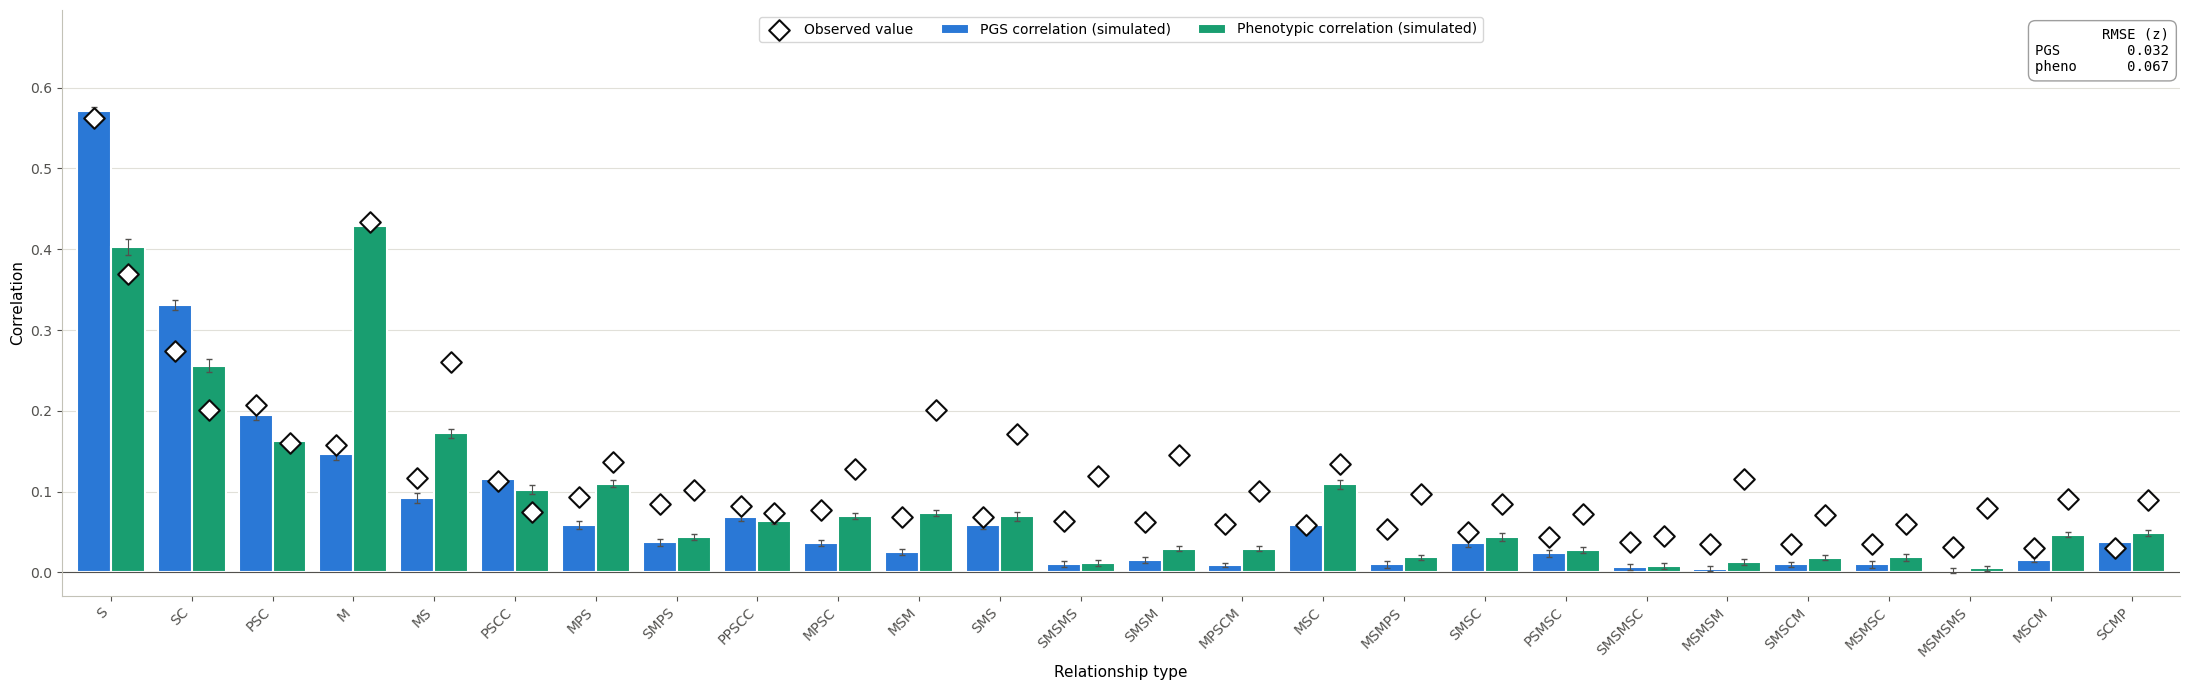


Trait 1 (AE): simulated vs observed


correlations,n,RMSE (z),bias (z)
"PGS, 16 fit types",16,0.0278,-0.0221
"PGS, 10 new types",10,0.0383,-0.0186
"PGS, all 26 types",26,0.0323,-0.0207
"phenotypic, 16 fit types",16,0.0737,-0.0558
"phenotypic, 10 new types",10,0.0544,-0.0348
"phenotypic, all 26 types",26,0.0669,-0.0477


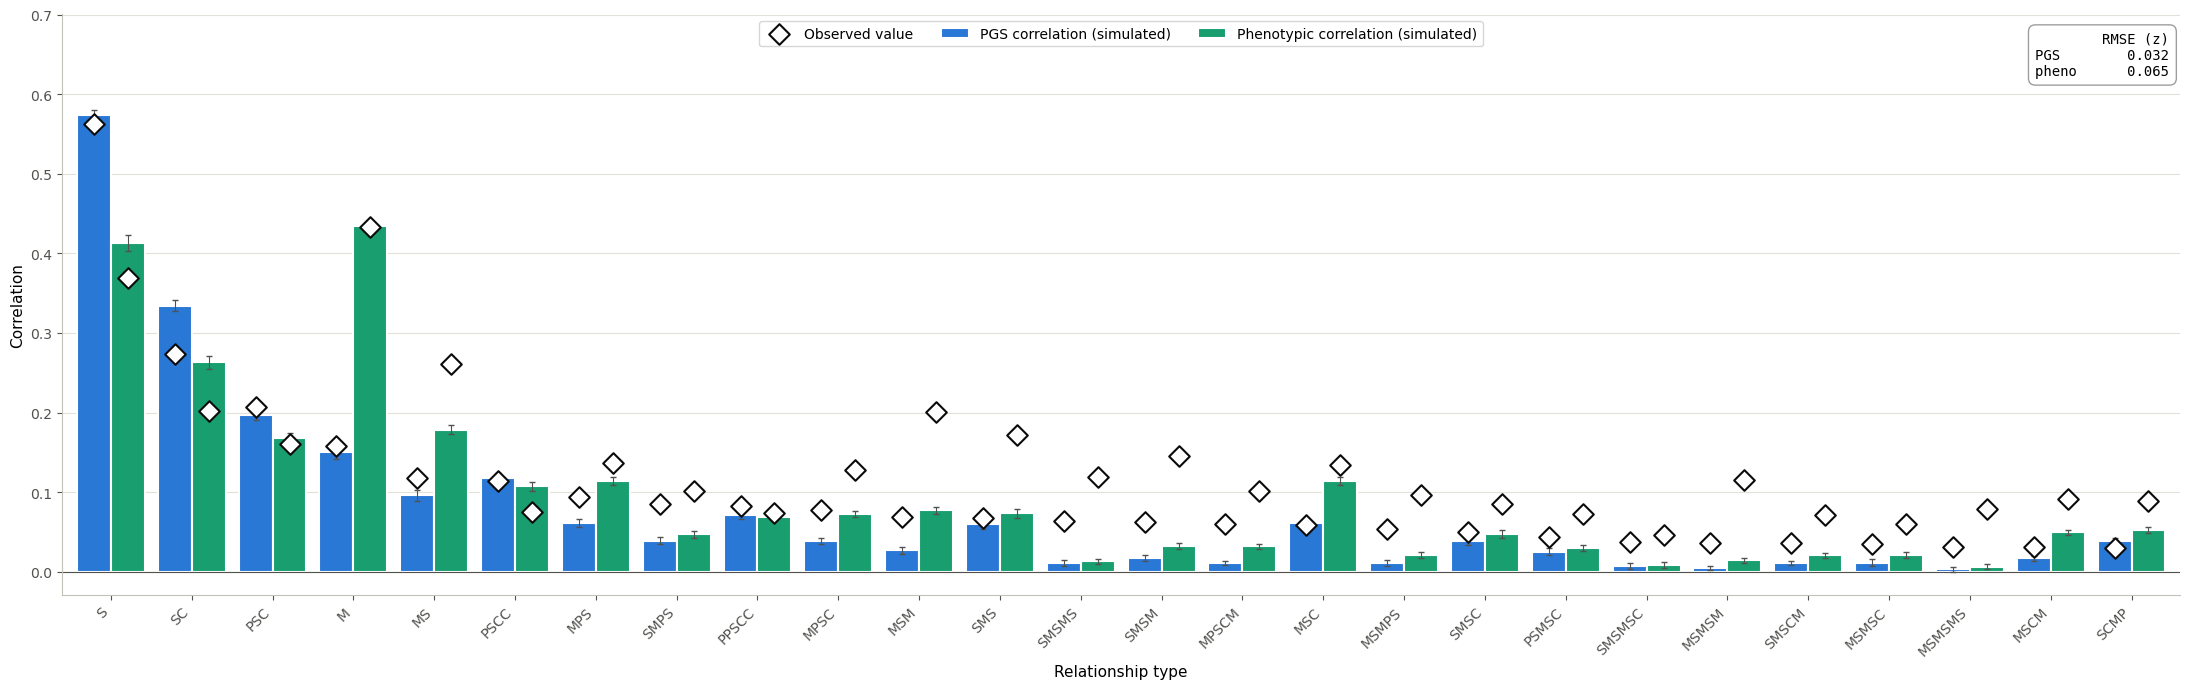


Trait 2 (AFE): simulated vs observed


correlations,n,RMSE (z),bias (z)
"PGS, 16 fit types",16,0.0269,-0.0202
"PGS, 10 new types",10,0.0380,-0.0170
"PGS, all 26 types",26,0.0316,-0.0190
"phenotypic, 16 fit types",16,0.0719,-0.0519
"phenotypic, 10 new types",10,0.0533,-0.0312
"phenotypic, all 26 types",26,0.0653,-0.0440


In [5]:
plot_condition("01DirAM")

## Condition 02 — AE latent AM (trait 1 = EA)

Trait 1 is EA (AE model: a PGS part and a latent genetic part plus unique environment). Mating is
phenotypic assortative mating on trait 2, a fully latent factor (no PGS) that is genetically (`rg`) and
environmentally (`re`) correlated with EA. No vertical transmission, no shared family environment. NPE
fit: `02AElatentAM`.

| Fixed parameter | Meaning | Value |
|---|---|---|
| `am11`, `am12`, `am21` | assortative mating (spousal correlations) | 0 |
| `f11`, `f22`, `f12`, `f21` | vertical transmission | 0 |
| `prop_h2_latent2` | share of trait-2 genetic variance not captured by a PGS | 1 |
| `vg2` | sets the trait-2 environmental variance 1 − `vg2` | 0.5 |
| `s11`, `s12`, `s21`, `s22` | shared family environment (no effect: the engine ignores `s`) | 0 |
| **Simulation** | | |
| generations | generations simulated (generations analysed) | 20 (analysed 17–19) |
| iterations | simulation replicates | 100 |

**Estimated parameters:**

In [6]:
parameter_table("02AElatentAM")

02AElatentAM: 0.0% of the unrestricted posterior inside the simulated range -> mcmc sampling (20,000 draws)


NPE fit,parameter,meaning,estimate,posterior SD,95% interval,simulated range,position in range,EA4 PGS + old pheno,change
02AElatentAM,prop_h2_latent1,share of trait-1 genetic variance not captured by the PGS,0.7894,0.0468,0.691 – 0.887,0.30 – 0.90,82%,0.7929,-0.0035
02AElatentAM,vg1,sets the trait-1 environmental variance 1 − vg1 (founder h² ≈ 1/(2 − vg1)),0.2296,0.0306,0.201 – 0.313,0.20 – 0.80,5%,0.2285,0.0011
02AElatentAM,re,environmental correlation between the traits,0.5425,0.0340,0.435 – 0.597,0.00 – 0.60,90%,0.5523,-0.0098
02AElatentAM,am22,spousal correlation on trait 2,0.7449,0.0043,0.734 – 0.750,0.25 – 0.75,99%,0.7451,-0.0003
02AElatentAM,rg,genetic correlation between the traits,0.8157,0.0275,0.765 – 0.885,0.20 – 0.90,88%,0.8219,-0.0061


As in the earlier run, none of the unrestricted posterior lies inside the simulated range; `am22` sits
at the upper end of it and `vg1` at the lower end. In the figure, nearly every correlation is too high:
the bias (mean z difference) is 0.03 for the PGS correlations, and 0.09 for the phenotypic ones of the
fit types and 0.12 of the new types.

Condition 02 — AE latent AM: results_npe_unweighted_02AElatentAM/predictions_ea4pheno/summary_statistics_02AElatentAM_ea4pheno.csv (100 replicates)


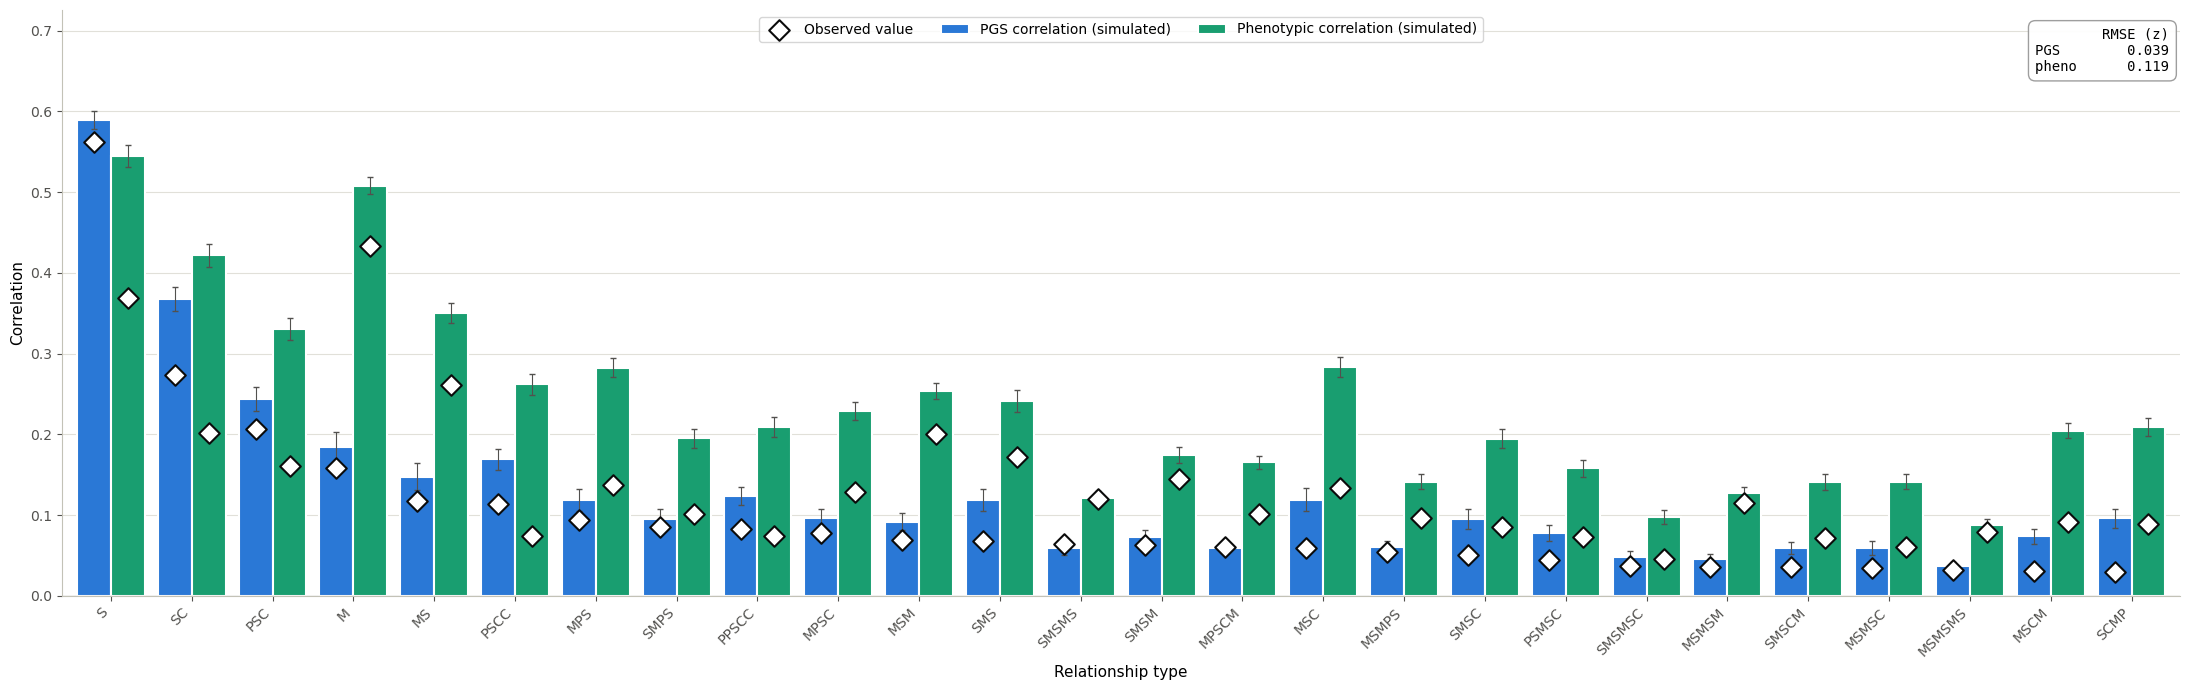


Trait 1 (EA): simulated vs observed


correlations,n,RMSE (z),bias (z)
"PGS, 16 fit types",16,0.0331,0.0280
"PGS, 10 new types",10,0.0472,0.0356
"PGS, all 26 types",26,0.0391,0.0309
"phenotypic, 16 fit types",16,0.1075,0.0881
"phenotypic, 10 new types",10,0.1345,0.1211
"phenotypic, all 26 types",26,0.1186,0.1008


In [7]:
plot_condition("02AElatentAM")

## Condition 03 — Environmental latent AM (trait 1 = EA)

As condition 02 (mating on the fully latent trait 2, genetically correlated with EA), plus within-trait
vertical transmission on both traits (`f11`, `f22`) and shared family environment (`s = 0.5`, which the
engine ignores); the environmental correlation is fixed at `re = 0.1` and `prop_h2_latent1` at 0.7.
NPE fit: `03EnvLatentAM` (training data `nn_training_03EnvLatentAM_all.csv`).

| Fixed parameter | Meaning | Value |
|---|---|---|
| `prop_h2_latent1` | share of trait-1 genetic variance not captured by the PGS | 0.7 |
| `re` | environmental correlation between the traits | 0.1 |
| `am11`, `am12`, `am21` | assortative mating (spousal correlations) | 0 |
| `prop_h2_latent2` | share of trait-2 genetic variance not captured by a PGS | 1 |
| `vg2` | sets the trait-2 environmental variance 1 − `vg2` | 0.5 |
| `s11`, `s12`, `s21`, `s22` | shared family environment (no effect: the engine ignores `s`) | 0.5 |
| `f12`, `f21` | cross-trait vertical transmission | 0 |
| **Simulation** | | |
| generations | generations simulated (generations analysed) | 20 (analysed 17–19) |
| iterations | simulation replicates | 100 |

**Estimated parameters:**

In [8]:
parameter_table("03EnvLatentAM")

03EnvLatentAM: 0.0% of the unrestricted posterior inside the simulated range -> mcmc sampling (20,000 draws)


NPE fit,parameter,meaning,estimate,posterior SD,95% interval,simulated range,position in range,EA4 PGS + old pheno,change
03EnvLatentAM,vg1,sets the trait-1 environmental variance 1 − vg1 (founder h² ≈ 1/(2 − vg1)),0.7336,0.0786,0.576 – 0.800,0.40 – 0.80,83%,0.7078,0.0258
03EnvLatentAM,f11,"vertical transmission, trait 1",0.1584,0.0794,0.081 – 0.254,0.05 – 0.30,43%,0.2131,-0.0547
03EnvLatentAM,f22,"vertical transmission, trait 2",0.0575,0.0035,0.053 – 0.064,0.05 – 0.30,3%,0.0598,-0.0023
03EnvLatentAM,am22,spousal correlation on trait 2,0.7303,0.0072,0.714 – 0.743,0.25 – 0.75,96%,0.7357,-0.0054
03EnvLatentAM,rg,genetic correlation between the traits,0.8982,0.0018,0.894 – 0.900,0.30 – 0.90,100%,0.8981,0.0001


None of the unrestricted posterior lies inside the simulated range: `rg` and `am22` sit at the upper
end of it with very small posterior SDs. `f11` is 0.055 lower than in the earlier run (within its
posterior SD of 0.079), which lowers the simulated correlations a little. In the figure, every
correlation is still too high, for the new types as for the fit types: the bias (mean z difference) is
about 0.09 for the PGS correlations and 0.23–0.25 for the phenotypic ones. The
[last section](#condition-03-with-the-updated-data) rechecks why.

Condition 03 — Environmental latent AM: results_npe_unweighted_03EnvLatentAM/predictions_ea4pheno/summary_statistics_03EnvLatentAM_ea4pheno.csv (100 replicates)


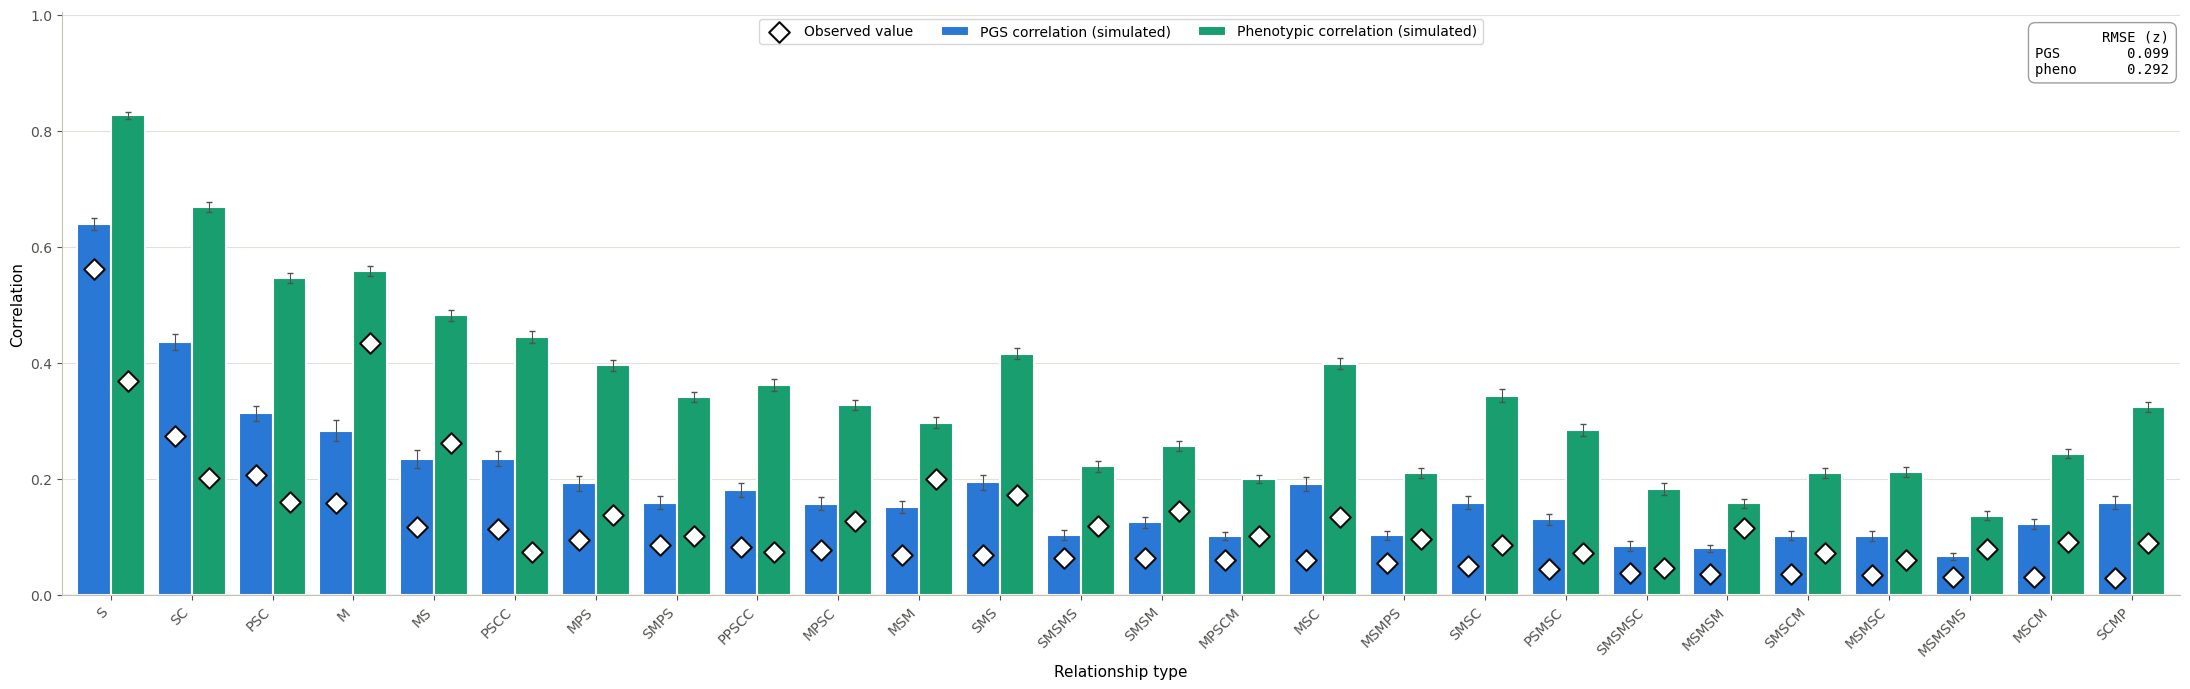


Trait 1 (EA): simulated vs observed


correlations,n,RMSE (z),bias (z)
"PGS, 16 fit types",16,0.0955,0.0891
"PGS, 10 new types",10,0.1032,0.0947
"PGS, all 26 types",26,0.0985,0.0912
"phenotypic, 16 fit types",16,0.2931,0.2336
"phenotypic, 10 new types",10,0.2903,0.2512
"phenotypic, all 26 types",26,0.2920,0.2404


In [9]:
plot_condition("03EnvLatentAM")

## Condition 04 — EA-driven migration (trait 1 = EA)

EA is additive genetics (a PGS part and a latent part) plus unique environment: no assortative mating
(random mating within islands), no vertical transmission, no shared environment. There are 5 islands;
each generation a fraction `move_p` of each sex on each island migrates, and the movers are sorted on EA,
so high-EA movers end up on the high-numbered islands. The population starts from random founders and
runs `n_gen` generations. Trait 2 is an inert dummy required by the bivariate engine. NPE fit:
`04EAmigration`.

| Fixed parameter | Meaning | Value |
|---|---|---|
| `vg2` | dummy trait 2: environmental variance 1 − `vg2` | 0.5 |
| `prop_h2_latent2` | dummy trait 2: fully latent | 1 |
| `rg`, `re` | genetic and environmental correlation between the traits | 0 |
| `f11`, `f12`, `f21`, `f22` | vertical transmission | 0 |
| `am11`, `am12`, `am21`, `am22` | assortative mating (spousal correlations) | 0 |
| **Simulation** | | |
| generations | generations simulated (generations analysed) | `n_gen` = 4 (analysed 1–3) |
| iterations | simulation replicates | 100 |

**Estimated parameters** (`n_gen`: posterior mode):

In [10]:
parameter_table("04EAmigration")

04EAmigration: 100.0% of the unrestricted posterior inside the simulated range -> rejection sampling (4,000 draws)


NPE fit,parameter,meaning,estimate,posterior SD,95% interval,simulated range,position in range,EA4 PGS + old pheno,change
04EAmigration,move_p,fraction of each sex per island migrating each generation,0.4454,0.0040,0.437 – 0.453,0.01 – 0.70,63%,0.4541,-0.0087
04EAmigration,n_gen,generations since the random founders (categorical posterior),4.0000,0.0000,4.000 – 4.000,3.00 – 10.00,14%,4.0000,0.0000
04EAmigration,vg1,sets the trait-1 environmental variance 1 − vg1 (founder h² ≈ 1/(2 − vg1)),0.3294,0.0376,0.264 – 0.411,0.20 – 0.80,22%,0.3118,0.0176
04EAmigration,prop_h2_latent1,share of trait-1 genetic variance not captured by the PGS,0.7136,0.0263,0.663 – 0.768,0.30 – 0.90,69%,0.7132,0.0005


The whole posterior lies inside the simulated range (plain rejection sampling), and `n_gen` = 4 has
posterior probability above 0.9999. The observed correlations are nonetheless outside the simulated
distribution jointly (see the last section), so the very narrow posterior intervals are overconfident.

In the figure, 04 fits the fit types best of the four conditions, PGS and phenotypic. It over-predicts
the phenotypic correlations of all 10 new types, most of all three in-law types (`MSCM` 0.20 simulated
against 0.09 observed, `MPSCM` 0.19 against 0.10, `SCMP` 0.16 against 0.09), while their PGS
correlations match.

Condition 04 — EA-driven migration: results_npe_unweighted_04EAmigration/predictions_ea4pheno/summary_statistics_04EAmigration_ea4pheno.csv (100 replicates)


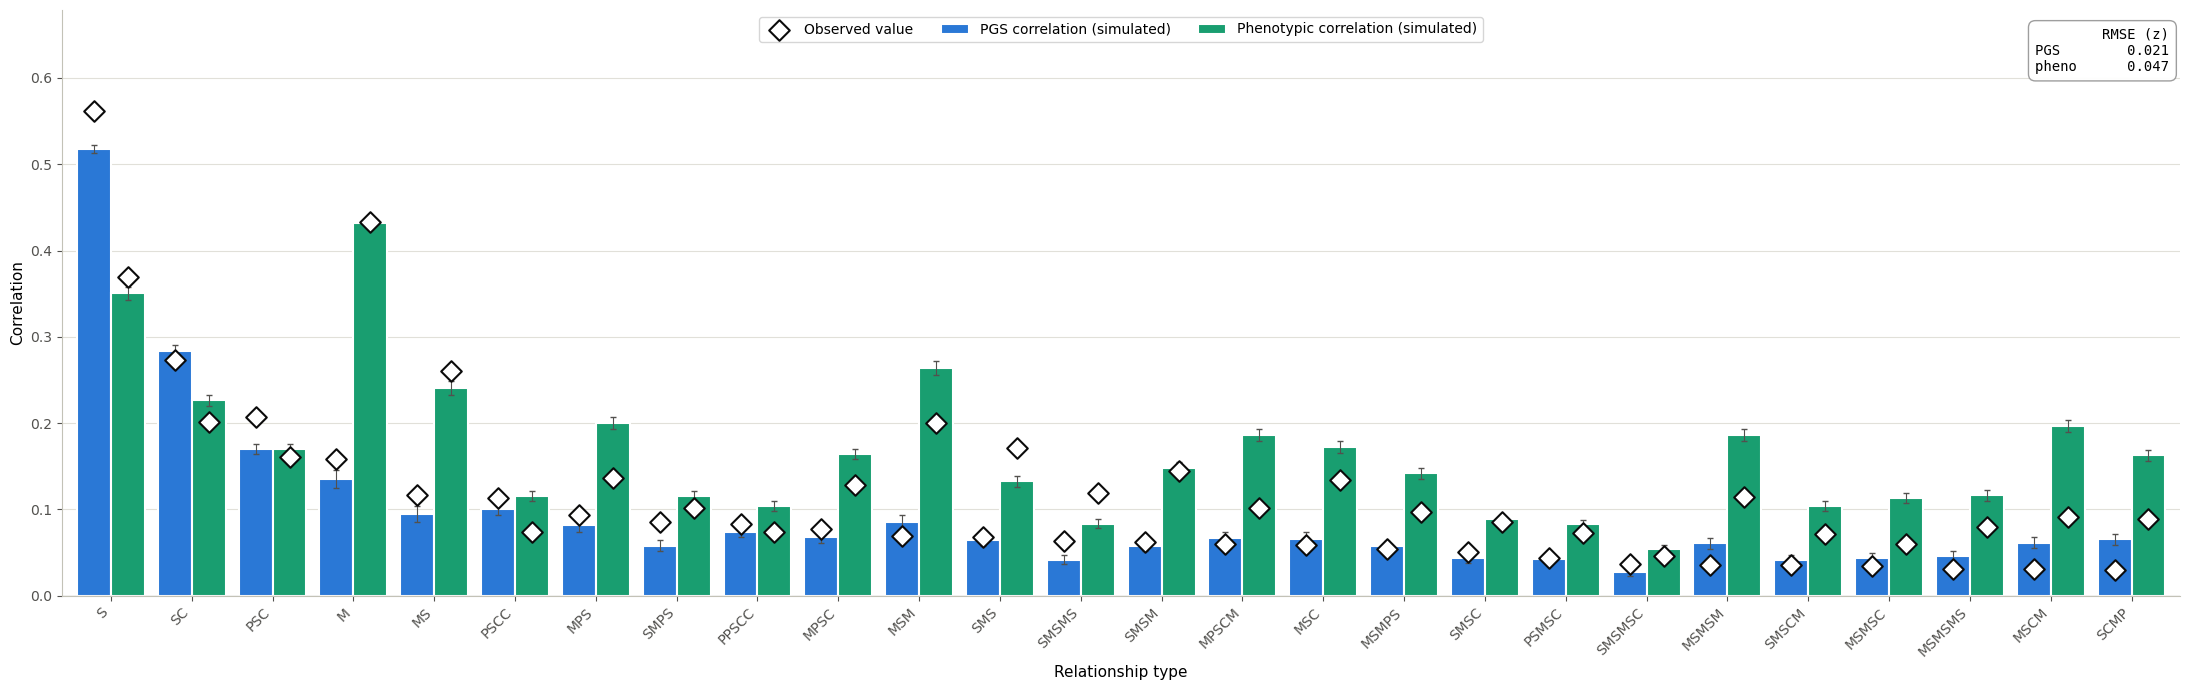


Trait 1 (EA): simulated vs observed


correlations,n,RMSE (z),bias (z)
"PGS, 16 fit types",16,0.0229,-0.0081
"PGS, 10 new types",10,0.0189,0.0033
"PGS, all 26 types",26,0.0215,-0.0037
"phenotypic, 16 fit types",16,0.0360,0.0137
"phenotypic, 10 new types",10,0.0602,0.0533
"phenotypic, all 26 types",26,0.0468,0.0289


In [11]:
plot_condition("04EAmigration")

## Condition 03 with the updated data

`Analysis_NPE_ea4new.ipynb` traced condition 03's poor fit to two problems: the model cannot make
spouses more alike on EA than siblings, and the NPE, asked about data the model cannot produce,
extrapolates to the edge of the simulated range. The cells below repeat the evidence with the updated
observed correlations and this run's simulations.

They use the training data of each NPE fit (the `nn_training_*.csv` files and row filters of
`run_npe_pipeline.py`) and the 20–30 features each fit uses (`run_specs/<fit>/features.txt`). They
compare each condition's observed data with its training simulations, with the simulation at this run's
estimate, and with the best-fitting training simulation (smallest Fisher-z RMSE over the fit's
features). A
training simulation is a single replicate, so the best of ~20,000 of them is slightly favoured by noise;
the predicted condition averages 100 replicates.

In [12]:
# training data of each NPE fit, as in run_npe_pipeline.py (RUNS): file and row filter
TRAINING = {"01DirAM_AE": ("01DirAM", "param_vg2.notna()"), "01DirAM_AFE": ("01DirAM", "param_vg2.notna()"),
            "02AElatentAM": ("02AElatentAM", None), "03EnvLatentAM": ("03EnvLatentAM_all", None),
            "04EAmigration": ("04EAmigration", None)}
SUMMARY_OF = {"01DirAM_AE": "01DirAM_AE", "01DirAM_AFE": "01DirAM_AE", "02AElatentAM": "02AElatentAM",
              "03EnvLatentAM": "03EnvLatentAM", "04EAmigration": "04EAmigration"}
_training_files = {}


def features(fit):
    return (script_dir / "run_specs" / fit / "features.txt").read_text().split()


def fit_params(fit):
    return (script_dir / "run_specs" / fit / "params.txt").read_text().split()


def training_data(fit):
    """Training simulations of an NPE fit with all its features present."""
    data, row_filter = TRAINING[fit]
    if data not in _training_files:
        _training_files[data] = pd.read_csv(script_dir / f"nn_training_{data}.csv")
    d = _training_files[data]
    return (d.query(row_filter) if row_filter else d).dropna(subset=features(fit))


def observed(feats):
    """Observed values of NPE features such as S_PGS1 or M_Y2 (EA4 PGS; updated phenotypic)."""
    return pd.Series({f: (obs_pgs if "_PGS" in f else obs_pheno)[f.rsplit("_", 1)[0]] for f in feats})


def simulated(fit, feats):
    """Mean over replicates of the predicted condition at this run's estimate, for an NPE fit's features."""
    s = pd.read_csv(pred_path(SUMMARY_OF[fit]))
    return pd.Series({f"{r.RelationshipPath}_{r.Variable}": r.Correlation_Mean for r in s.itertuples()})[feats]


rows = []
for fit in TRAINING:
    feats = features(fit)
    d, obs = training_data(fit), observed(feats)
    X = d[feats]
    mean, prec = X.mean().to_numpy(), np.linalg.pinv(np.cov(X.to_numpy(), rowvar=False))

    def mahalanobis(v):
        z = np.atleast_2d(v - mean)
        return np.sqrt(np.einsum("ij,jk,ik->i", z, prec, z))

    rmse = np.sqrt((z_diff(X, obs) ** 2).mean(axis=1))
    est_rmse = np.sqrt((z_diff(simulated(fit, feats), obs) ** 2).mean())
    outside = [f"{f} ({obs[f]:.3f}; simulated {X[f].min():.3f}–{X[f].max():.3f})"
               for f in feats if not X[f].min() <= obs[f] <= X[f].max()]
    rows.append({"NPE fit": fit, "training simulations": len(d), "features": len(feats),
                 "Mahalanobis: observed": mahalanobis(obs.to_numpy())[0],
                 "Mahalanobis: training max": mahalanobis(X.to_numpy()).max(),
                 "observed outside the simulated range": "; ".join(outside) or "–",
                 "RMSE (z): best training simulation": rmse.min(),
                 "RMSE (z): at the estimate": est_rmse,
                 "simulations fitting better than the estimate": f"{(rmse < est_rmse).mean():.1%}"})
show(pd.DataFrame(rows), precision=3)

NPE fit,training simulations,features,Mahalanobis: observed,Mahalanobis: training max,observed outside the simulated range,RMSE (z): best training simulation,RMSE (z): at the estimate,simulations fitting better than the estimate
01DirAM_AE,19593,20,19.897,10.554,–,0.031,0.034,0.4%
01DirAM_AFE,19593,20,14.389,9.183,–,0.034,0.033,0.0%
02AElatentAM,18138,20,21.083,9.870,–,0.037,0.077,23.6%
03EnvLatentAM,38124,20,22.066,10.645,S_Y1 (0.369; simulated 0.370–0.923),0.069,0.231,97.8%
04EAmigration,19968,30,26.127,11.058,–,0.028,0.031,0.1%


- **All four conditions are out of distribution jointly**, as before. The observed data are 14–26
  Mahalanobis units from the training mean, while no training simulation is further than ~11.
- **Only in 03 does a single observed correlation fall outside the simulated range:** the sibling
  phenotypic correlation, now 0.369, just below the lowest of the 38,124 training simulations (0.370).
- **For 01 and 04, the simulation at the estimate fits about as well as the best training simulation.**
  For 02 it is worse than 24% of the training simulations, and for 03 worse than 98% of them.

### The spousal–sibling trade-off

Every training simulation of conditions 02 and 03 by its spousal (`M_Y1`) and sibling (`S_Y1`)
phenotypic EA correlation, with the updated observed values, the simulation at this run's estimate and
the best-fitting training simulation.

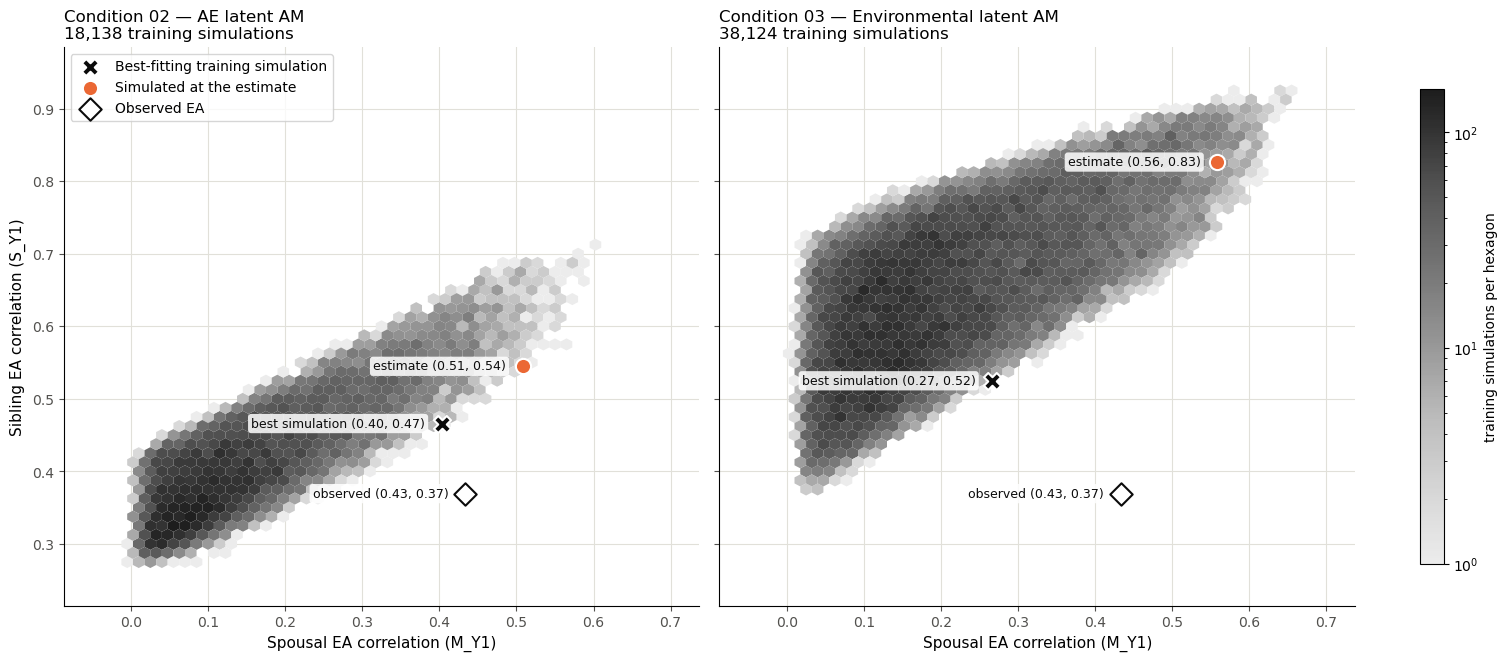

02AElatentAM: 817 of 18,138 simulations have M_Y1 >= 0.40; their S_Y1 is 0.466 or more (median 0.588). Lowest S_Y1 of all simulations: 0.274 (observed 0.369).
03EnvLatentAM: 4,109 of 38,124 simulations have M_Y1 >= 0.40; their S_Y1 is 0.611 or more (median 0.792). Lowest S_Y1 of all simulations: 0.370 (observed 0.369).


In [13]:
# grey ramp from light grey (one simulation) to near-black, so sparse hexagons stay visible
DENSITY = LinearSegmentedColormap.from_list("density", plt.cm.Greys(np.linspace(0.15, 0.9, 256)))
SHORT_LABEL = {"Best-fitting training simulation": "best simulation", "Simulated at the estimate": "estimate",
               "Observed EA": "observed"}
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), sharex=True, sharey=True, layout="constrained")
hexbins = []
for ax, fit in zip(axes, ("02AElatentAM", "03EnvLatentAM")):
    feats = features(fit)
    d, obs = training_data(fit), observed(feats)
    best = d.loc[(z_diff(d[feats], obs) ** 2).mean(axis=1).idxmin()]
    est = simulated(fit, feats)
    hexbins.append(ax.hexbin(d["M_Y1"], d["S_Y1"], gridsize=50, cmap=DENSITY, mincnt=1, linewidths=0,
                             extent=(-0.05, 0.7, 0.25, 0.95)))
    points = (("Best-fitting training simulation", best, dict(marker="X", s=150, color=INK)),
              ("Simulated at the estimate", est, dict(marker="o", s=120, color=ACCENT)),
              ("Observed EA", obs, dict(marker="D", s=130, facecolor="white", edgecolor=INK)))
    for label, p, style in points:
        style = {"edgecolor": "white", **style}
        ax.scatter(p["M_Y1"], p["S_Y1"], linewidth=1.5, zorder=5, label=label, **style)
        ax.annotate(f"{SHORT_LABEL[label]} ({p['M_Y1']:.2f}, {p['S_Y1']:.2f})", (p["M_Y1"], p["S_Y1"]),
                    xytext=(-12, 0), textcoords="offset points", ha="right", va="center", fontsize=9,
                    color=INK, bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="none", alpha=0.85))
    ax.set_title(f"{CONDITIONS[fit]['title']}\n{len(d):,} training simulations", loc="left", fontsize=12)
    ax.set_xlabel("Spousal EA correlation (M_Y1)", fontsize=11)
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.tick_params(colors=MUTED)
axes[0].set_ylabel("Sibling EA correlation (S_Y1)", fontsize=11)
axes[0].legend(loc="upper left", fontsize=10, frameon=True)
norm = LogNorm(vmin=1, vmax=max(h.get_array().max() for h in hexbins))
for h in hexbins:
    h.set_norm(norm)
fig.colorbar(hexbins[-1], ax=axes, label="training simulations per hexagon", shrink=0.85)
plt.show()

for fit in ("02AElatentAM", "03EnvLatentAM"):
    d = training_data(fit)
    high = d[d["M_Y1"] >= 0.40]
    print(f"{fit}: {len(high):,} of {len(d):,} simulations have M_Y1 >= 0.40; their S_Y1 is "
          f"{high['S_Y1'].min():.3f} or more (median {high['S_Y1'].median():.3f}). "
          f"Lowest S_Y1 of all simulations: {d['S_Y1'].min():.3f} (observed {obs_pheno['S']:.3f}).")

The observed point (spouses 0.43, siblings 0.37) still lies below both clouds. In 03, every
simulation with a spousal correlation of 0.40 or more has a sibling correlation of at least 0.61. The
estimate lands at the opposite, upper-right end of the 03 cloud; the best simulation matches the PGS
correlations but has siblings at 0.52 and spouses at 0.27.

The reason is the one given in `Analysis_NPE_ea4new.ipynb`. In condition 03, spouses resemble each other
on EA only because they mate on trait 2, and with `re` fixed at 0.1 that link is almost entirely genetic
(`rg`). Strong spousal resemblance therefore means genetic assortment on EA, which also makes siblings
alike. Vertical transmission (`f11` ≥ 0.05) and a heritability of at least about 0.63 (`vg1` ≥ 0.4) add
to the sibling correlation. Condition 02 estimates `re` (up to 0.6), which makes spouses alike without
making relatives genetically alike; its cloud comes closer, but does not reach the observed point either.

### This run's estimate versus the best training simulations

In [14]:
fit = "03EnvLatentAM"
feats, params = features(fit), fit_params(fit)
d, obs = training_data(fit), observed(feats)
pgs_f, ph_f = [f for f in feats if "_PGS" in f], [f for f in feats if "_Y" in f]
shown = ["S_Y1", "PSC_Y1", "M_Y1", "MS_Y1", "S_PGS1", "M_PGS1"]


def fit_summary(values):
    z2 = z_diff(values[feats].astype(float), obs) ** 2
    return {"RMSE (z)": np.sqrt(z2.mean()), "PGS RMSE (z)": np.sqrt(z2[pgs_f].mean()),
            "pheno RMSE (z)": np.sqrt(z2[ph_f].mean()), **values[shown].astype(float)}


estimate = pd.read_csv(script_dir / f"results_npe_unweighted_{fit}" / "predictions_ea4pheno" /
                       "posterior_summary.csv").set_index("parameter")["mean"]
rmse = np.sqrt((z_diff(d[feats], obs) ** 2).mean(axis=1))
rows = [{"": "observed", **obs[shown]},
        {"": "simulated at the estimate (100 replicates)", **estimate[params],
         **fit_summary(simulated(fit, feats))}]
for i in rmse.nsmallest(5).index:
    rows.append({"": f"training simulation {d.loc[i, 'Condition']}",
                 **{p: d.loc[i, f"param_{p}"] for p in params}, **fit_summary(d.loc[i])})
show(pd.DataFrame(rows)[["", *params, "RMSE (z)", "PGS RMSE (z)", "pheno RMSE (z)", *shown]], precision=3)

,vg1,f11,f22,am22,rg,RMSE (z),PGS RMSE (z),pheno RMSE (z),S_Y1,PSC_Y1,M_Y1,MS_Y1,S_PGS1,M_PGS1
observed,–,–,–,–,–,–,–,–,0.369,0.160,0.433,0.261,0.562,0.158
simulated at the estimate (100 replicates),0.734,0.158,0.057,0.730,0.898,0.231,0.095,0.480,0.826,0.546,0.559,0.482,0.639,0.283
training simulation Condition_19965,0.417,0.050,0.219,0.556,0.762,0.069,0.015,0.151,0.525,0.276,0.267,0.223,0.567,0.137
training simulation Condition_17436,0.415,0.058,0.089,0.481,0.884,0.069,0.022,0.148,0.514,0.238,0.256,0.178,0.564,0.129
training simulation Condition_13697,0.460,0.059,0.272,0.485,0.883,0.069,0.017,0.151,0.537,0.266,0.277,0.224,0.560,0.126
training simulation Condition_17859,0.413,0.056,0.155,0.644,0.644,0.070,0.015,0.153,0.545,0.285,0.296,0.234,0.558,0.123
training simulation Condition_05497,0.444,0.060,0.134,0.563,0.776,0.070,0.017,0.152,0.539,0.267,0.281,0.214,0.556,0.126


- **The estimate moves away from the data.** Compared with the five best training simulations, it has
  higher `vg1` (0.73 against 0.41–0.46) and `f11` (0.16 against 0.05–0.06), both of which raise the
  relatives' correlations. Its PGS RMSE is 0.095, against 0.015–0.022 for the best simulations.
- **The best simulations still miss the phenotypic correlations** (siblings 0.51–0.55 against 0.37,
  spouses 0.26–0.30 against 0.43): that part of the misfit belongs to the model, not to the NPE.
- **The conclusions are unchanged.** Do not read the 03 posterior means as estimates: the posterior is
  driven by the range boundary, not by the data. The wider-prior design (`Scripts/run_rc_paper_wider`)
  lowers the bounds of `vg1` and `f11` but still fixes `re` = 0.1. Estimating `re`, as condition 02
  does, is the direct way to let spouses be more alike than siblings.